# DS2002 · Weather API Join

**Studio — 2026-10-21 · Fall 2026**  

---

## Start here: charters in, repos started

Nothing is due from this session. There is no checkpoint and nothing to paste into Canvas for today's work. This is team time.

Before you touch the weather API, make sure the team basics from Monday are done. Everything after this depends on them. Go down this list as a team. It is the same list from the end of Monday's kickoff.

- Charter filled in, the charter cell run, and `CHARTER.md` written
- `CHARTER.md` committed to the root of your team repo
- Charter and repo link submitted in Canvas
- Repo created, everyone has push access, and everyone has cloned it
- One person named as this week's notebook owner
- A recurring meeting time on everyone's calendar
- Data profile run on the real file, with your five worst problems listed

If something on that list is missing, fix it first. It is the most useful thing you can do today.

Everything below is a set of recipes. There is nothing to fill in. Run each one, read what it prints, and copy what you need into your team's notebook.

### Recipe: start the repo

This is the layout we set up on Monday:

```
walmart-hurricane-project/
├── CHARTER.md
├── README.md
├── data/
└── notebooks/
    ├── team_notebook.ipynb
    └── scratch/
```

One person creates the repo and pushes it. In a terminal, replace the URL with your own repo's:

```
mkdir -p walmart-hurricane-project/data walmart-hurricane-project/notebooks/scratch
cd walmart-hurricane-project
touch notebooks/scratch/.gitkeep
echo "# Our team name" > README.md
git init -b main
git add .
git commit -m "Start project"
git remote add origin https://github.com/your-account/walmart-hurricane-project.git
git push -u origin main
```

Then everyone else clones it:

```
git clone https://github.com/your-account/walmart-hurricane-project.git
```

Copy the five data files into `data/` and put the first version of `team_notebook.ipynb` in `notebooks/`, then commit and push those too.

If your charter is not a file yet, run the last two cells of Monday's kickoff notebook. Move the `CHARTER.md` it writes to the root of the repo and commit it:

```
git add CHARTER.md
git commit -m "Add team charter"
git push
```

Habit for the rest of the project: `git pull` before you start, `git push` before you stop.

Run this once your clone is on your machine. Point `MY_REPO` at the folder. It checks that the pieces from the layout above are there.

In [1]:
from pathlib import Path

def check_repo(root):
    root = Path(root)
    needed = ['CHARTER.md', 'README.md', 'data', 'notebooks/team_notebook.ipynb', 'notebooks/scratch']
    ok = True
    for item in needed:
        found = (root / item).exists()
        print('PASS' if found else 'FAIL', '-', item)
        ok = ok and found
    print()
    print('repo ready:', ok)
    return ok

MY_REPO = '../../'
check_repo(MY_REPO)

PASS - CHARTER.md
PASS - README.md
PASS - data
PASS - notebooks/team_notebook.ipynb
PASS - notebooks/scratch

repo ready: True


True

## The storm

Hurricane Helene made landfall on the Florida Big Bend late on **September 26, 2024**. That is the landfall date for this project. The sales data is built around it, and the real weather you pull from the API lines up with it.

Here is what daily orders look like in the transactions file. These are counted after dropping exact duplicates and rows with no timestamp, so your own numbers will differ a little.

| Dates | Orders per day | What is happening |
|---|---|---|
| Sept 1–15 | about 580 | Normal. This is your baseline. |
| Sept 16–20 | about 780 | The first rise |
| Sept 21–23 | about 1,350 | People are stocking up |
| Sept 24–25 | about 2,000 | The peak, the two days before landfall |
| Sept 26 | about 1,140 | Landfall. Orders fall back to about half the peak. |
| Sept 27–28 | about 860 | Recovery |
| Sept 29–30 | about 570 | Back to normal |

Use Sept 26 as landfall for the windows in Question 1 and the lag in Question 3.

If you downloaded or cloned the data files before Wednesday, get a fresh copy. We moved the dates in the transactions file and the inventory database so they line up with Helene, and an older copy will not match this notebook.

## The join that eats a week of your project

Question 3 needs weather next to sales, one row per day. It sounds like a five-minute merge. In practice it is where teams lose days, and always to the same four problems:

1. Sales dates are timestamps; weather dates are dates. They never match.
2. One side is a string, the other a datetime. They never match, and pandas does not warn you.
3. The API returns a full calendar range; your sales only cover some of those days. An inner join silently discards the rest.
4. The correlation comes out strong on three data points, and somebody puts it in a deck.

Today you hit all four deliberately on three weeks of real daily orders, so you recognize them at a hundred thousand.

In [2]:
%pip install pandas numpy requests

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd, numpy as np, requests, time

# Daily orders from the real transactions file, Sept 8-28, 2024. Note: these are timestamps, not dates.
# (A daily total has no clock time, so we added one. That is what makes this a realistic mess.)
days = pd.date_range('2024-09-08', '2024-09-28')
clock = ['08:14', '09:02', '10:41', '08:33', '11:20', '07:55', '09:10',
         '12:02', '08:44', '10:15', '11:30', '08:05', '11:45', '09:22',
         '10:08', '07:48', '12:30', '09:37', '08:52', '10:26', '11:02']
sales = pd.DataFrame({
    'ts': pd.to_datetime([f'{d:%Y-%m-%d} {c}' for d, c in zip(days, clock)]),
    'orders': [590, 586, 577, 590, 587, 580, 586,
               566, 809, 767, 798, 783, 760, 1313,
               1367, 1374, 1968, 2007, 1139, 851, 879],
})
LANDFALL = pd.Timestamp('2024-09-26')
sales.head()

,ts,orders
0,2024-09-08 08:14:00,590
1,2024-09-09 09:02:00,586
2,2024-09-10 10:41:00,577
3,2024-09-11 08:33:00,590
4,2024-09-12 11:20:00,587


### Problem 1 — a timestamp is not a date

Watch this fail, because it will fail exactly this way in your project.

In [4]:
weather_dates = pd.to_datetime(['2024-09-25', '2024-09-26', '2024-09-27'])
tiny = pd.DataFrame({'date': weather_dates, 'rain_mm': [6.4, 15.2, 2.5]})

broken = sales.merge(tiny, left_on='ts', right_on='date', how='inner')
print('rows matched:', len(broken))

rows matched: 0


Zero. `2024-09-26 08:52` is not equal to `2024-09-26 00:00`, and no amount of staring at the two tables will show you that, because they print identically at a glance.

**The fix:** add a `date` column to `sales` that is the timestamp cut back to midnight with `.dt.normalize()`, then merge on that instead. Same merge, three rows.

In [5]:
sales['date'] = sales['ts'].dt.normalize()

fixed = sales.merge(tiny, on='date', how='inner')
print('rows matched:', len(fixed))
fixed[['date', 'orders', 'rain_mm']]

rows matched: 3


,date,orders,rain_mm
0,2024-09-25,2007,6.4
1,2024-09-26,1139,15.2
2,2024-09-27,851,2.5


### Problem 2 — a string is not a datetime

The API hands back `time` as text. Merging text against datetimes gives you zero matches or, worse, a `ValueError` you will spend twenty minutes reading.

In [6]:
api_shape = pd.DataFrame({
    'time': ['2024-09-25', '2024-09-26', '2024-09-27'],   # strings!
    'rain_mm': [6.4, 15.2, 2.5],
})
print('api time dtype:  ', api_shape['time'].dtype)
print('sales ts dtype:  ', sales['ts'].dtype)
print()
print('Rule: convert on the API side immediately, before anything else touches it.')

api time dtype:   str
sales ts dtype:   datetime64[us]

Rule: convert on the API side immediately, before anything else touches it.


**The fix:** convert on the API side, right away, and give it the same name you will merge on.

In [7]:
api_shape['date'] = pd.to_datetime(api_shape['time'])
api_shape = api_shape.drop(columns='time')

print('api date dtype:  ', api_shape['date'].dtype)
print('sales date dtype:', sales['date'].dtype)
print('rows matched:    ', len(sales.merge(api_shape, on='date', how='inner')))

api date dtype:   datetime64[us]
sales date dtype: datetime64[us]
rows matched:     3


### Recipe 1 — the fetch

`daily_weather(start, end, lat, lon)` for Orlando (28.54, -81.38). It does the things you have built before:

- daily `precipitation_sum` and `windspeed_10m_max`
- a timeout, and a retry on 429 or 5xx
- converts `time` to a datetime column named `date` **inside the function**
- adds a `source` column so a fallback is never mistaken for real data

In [8]:
BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'timezone': 'America/New_York',
    }
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()                       # any other bad status fails loudly
        frame = pd.DataFrame(r.json()['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'
        return frame

# A saved copy of the same Open-Meteo data (Orlando, Sept 1-30, 2024) for when you have no wifi
# or the API is down. The source column says so.
FALLBACK = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=30),
    'precipitation_sum': [3.0, 12.4, 24.9, 22.1, 23.1, 9.3, 6.8, 94.7, 28.0, 14.4,
                          12.0, 0.7, 0.6, 21.1, 1.2, 7.9, 2.3, 13.3, 1.4, 0.7,
                          0.4, 2.2, 1.3, 0.3, 6.4, 15.2, 2.5, 18.0, 4.6, 3.3],
    'windspeed_10m_max': [18.8, 13.5, 22.8, 15.5, 15.2, 9.0, 14.2, 12.6, 11.5, 14.3,
                          15.8, 12.1, 10.4, 17.4, 9.0, 13.3, 12.4, 9.3, 12.9, 15.3,
                          19.9, 17.9, 16.6, 17.7, 27.2, 48.8, 45.1, 19.8, 11.7, 8.6],
    'source': 'fallback sample',
})

try:
    weather_live = daily_weather('2024-09-01', '2024-09-30')
except requests.RequestException as err:
    print('API call failed:', err)
    weather_live = FALLBACK

same = (np.allclose(weather_live['precipitation_sum'], FALLBACK['precipitation_sum'])
        and np.allclose(weather_live['windspeed_10m_max'], FALLBACK['windspeed_10m_max']))
print('source:', weather_live['source'].iloc[0])
print('matches the saved copy:', same)
weather_live.head()

source: open-meteo
matches the saved copy: True


,date,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,3.0,18.8,open-meteo
1,2024-09-02,12.4,13.5,open-meteo
2,2024-09-03,24.9,22.8,open-meteo
3,2024-09-04,22.1,15.5,open-meteo
4,2024-09-05,23.1,15.2,open-meteo


We asked for the whole month, and our sales only cover Sept 8–28. That mismatch is Problem 3 from the list at the top, and it is in the next recipe. Keep the `source` column all the way through your project so you always know which version you are looking at.

### Recipe 2 — the merge, validated

Join weather onto sales with a left join so no sales day disappears, and `indicator=True` so you can see what matched.

Then assert three things: the row count still equals the number of sales days, nothing is `right_only`, and the orders total is unchanged.

In [9]:
weather = weather_live        # works whether it came from the API or the saved copy

merged = sales.merge(weather, on='date', how='left', indicator=True)

assert len(merged) == len(sales), 'the join changed the row count'
assert not (merged['_merge'] == 'right_only').any(), 'weather rows with no sales day'   # a left join can't make these; this guards against someone changing how= later
assert merged['orders'].sum() == sales['orders'].sum(), 'the orders total changed'

outer = sales.merge(weather, on='date', how='outer', indicator=True)

print(merged['_merge'].value_counts())
print('weather days with no sales, dropped on purpose by the left join:', len(weather) - len(sales))
print('an outer join would have added', (outer['_merge'] == 'right_only').sum(), 'right_only rows with no orders')
print('all three checks passed')
merged.head()

_merge
both          21
left_only      0
right_only     0
Name: count, dtype: int64
weather days with no sales, dropped on purpose by the left join: 9
an outer join would have added 9 right_only rows with no orders
all three checks passed


,ts,orders,date,precipitation_sum,windspeed_10m_max,source,_merge
0,2024-09-08 08:14:00,590,2024-09-08,94.7,12.6,open-meteo,both
1,2024-09-09 09:02:00,586,2024-09-09,28.0,11.5,open-meteo,both
2,2024-09-10 10:41:00,577,2024-09-10,14.4,14.3,open-meteo,both
3,2024-09-11 08:33:00,590,2024-09-11,12.0,15.8,open-meteo,both
4,2024-09-12 11:20:00,587,2024-09-12,0.7,12.1,open-meteo,both


### Problem 3 — the days that did not match

If any sales day comes back with no weather, you need to know which, and decide what to do. Our weather matched every sales day, so break it on purpose first: drop the landfall day from the weather, which is the worst day to lose. Then look at what the check shows you.

In [10]:
weather_gap = weather[weather['date'] != LANDFALL]
gap = sales.merge(weather_gap, on='date', how='left', indicator=True)

unmatched = gap.loc[gap['_merge'] == 'left_only', 'date']
print('sales days with no weather:', len(unmatched))
print(unmatched.dt.date.tolist())
print('rows kept by the left join:', len(gap), 'of', len(sales))
print('rows an inner join would have kept:', len(sales.merge(weather_gap, on='date', how='inner')))

sales days with no weather: 1
[datetime.date(2024, 9, 26)]
rows kept by the left join: 21 of 21
rows an inner join would have kept: 20


**The decision, and why:** do not drop them for Question 3. The missing day here is landfall, the one day the question is about. An inner join removes it without a word and the chart still looks fine. Keep the row with a left join, print the dates, and write the choice in your decision log with the row count.

If the missing day is one you can live without, say so and say why. If it is not, go get that day of weather.

### Recipe 3 — the baseline, which is what makes a surge a surge

"Orders were 2,007 on Sept 25" means nothing alone. "Orders were 2,007 against a baseline of about 583 a day" is a finding.

The windows matter more than you would think. Orders sit flat at about 580 until Sept 15, then climb for ten days. A baseline that runs through the climb makes the surge look smaller. A surge window that includes landfall day, when orders fall back, does the same thing. Pick windows you can defend and say what they are.

Our baseline is Sept 8–15, the flat days before the first rise. Our surge is Sept 23–25, the three days before landfall.

In [11]:
def window(df, start, end):
    return df[(df['date'] >= start) & (df['date'] <= end)]

baseline = window(merged, '2024-09-08', '2024-09-15')    # flat, before the first rise
surge = window(merged, '2024-09-23', '2024-09-25')       # the three days before landfall

baseline_per_day = baseline['orders'].mean()
surge_per_day = surge['orders'].mean()
multiple = surge_per_day / baseline_per_day

print('baseline:', round(baseline_per_day, 1), 'orders/day over', len(baseline), 'days')
print('surge:   ', round(surge_per_day, 1), 'orders/day over', len(surge), 'days')
print('multiple:', round(multiple, 1), 'x')

print()
print('Same data, different windows:')
choices = {
    'baseline Sept 8-15, surge Sept 23-25 (ours)': ('2024-09-08', '2024-09-15', '2024-09-23', '2024-09-25'),
    'baseline Sept 8-22 (runs through the climb)': ('2024-09-08', '2024-09-22', '2024-09-23', '2024-09-25'),
    'surge Sept 24-26 (includes landfall day)':    ('2024-09-08', '2024-09-15', '2024-09-24', '2024-09-26'),
}
for name, (b0, b1, s0, s1) in choices.items():
    m = window(merged, s0, s1)['orders'].mean() / window(merged, b0, b1)['orders'].mean()
    print(f'{m:.1f}x  {name}')

baseline: 582.8 orders/day over 8 days
surge:    1783.0 orders/day over 3 days
multiple: 3.1 x

Same data, different windows:
3.1x  baseline Sept 8-15, surge Sept 23-25 (ours)
2.4x  baseline Sept 8-22 (runs through the climb)
2.9x  surge Sept 24-26 (includes landfall day)


Same orders, three different answers: about 3.1x, 2.4x, and 2.9x. Always say what the windows are when you quote the multiple, and put them in your decision log.

### Problem 4 — the correlation you should not report

Compute the correlation between orders and wind speed on all 21 days, then on just the 3 surge days. Then slide a 3-day window across the whole range and see what a three-point correlation does.

In [12]:
r_all = merged['orders'].corr(merged['windspeed_10m_max'])
r_surge = surge['orders'].corr(surge['windspeed_10m_max'])

print('all 21 days:   r =', round(r_all, 2))
print('3 surge days:  r =', round(r_surge, 2), '  (n =', len(surge), ')')

sliding = [merged['orders'].iloc[i:i + 3].corr(merged['windspeed_10m_max'].iloc[i:i + 3])
           for i in range(len(merged) - 2)]
print('every 3-day window in the data: r runs from', round(np.nanmin(sliding), 2), 'to', round(np.nanmax(sliding), 2))

all 21 days:   r = 0.35
3 surge days:  r = 0.62   (n = 3 )
every 3-day window in the data: r runs from -0.97 to 1.0


Three points can give you almost any correlation. Slide a 3-day window across the same data and r runs from -0.97 to 1.0. The surge-window number is just one of those. Do not put it in the presentation, whatever it says.

The 21-day number is weak too, around 0.35, but that does not mean wind and orders are unrelated. It means we compared the wrong days. The next recipe fixes that.

### Recipe 4 — the lag

Question 3 also asks whether purchasing leads the weather or follows it. Line each day's orders up against the wind some number of days later, and see where the correlation is strongest.

In [13]:
for k in range(0, 5):
    r = merged['orders'].corr(merged['windspeed_10m_max'].shift(-k))
    print(f'orders vs wind {k} day(s) later:  r = {r:.2f}')

orders vs wind 0 day(s) later:  r = 0.35
orders vs wind 1 day(s) later:  r = 0.70
orders vs wind 2 day(s) later:  r = 0.89
orders vs wind 3 day(s) later:  r = 0.72
orders vs wind 4 day(s) later:  r = 0.66


**What I would say in the presentation:** orders and wind speed barely move together on the same day (r = 0.35), but they line up strongly when you compare orders to the wind two days later (r = 0.89). People bought two days before the worst wind arrived. That is a lag, and it is the finding for the second half of Question 3. Say how many days the number is based on, and say that the surge-window correlation was thrown out because it rests on three points.

### Recipe 5 — the chart

Plot orders by date, mark landfall with a vertical line, put wind on a second axis, and title it with the finding rather than the topic. This chart goes in your deck, so apply the chart rules from the rubric now (clear title, labeled axes, a legend where it is needed) rather than rebuilding it later.

In [14]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


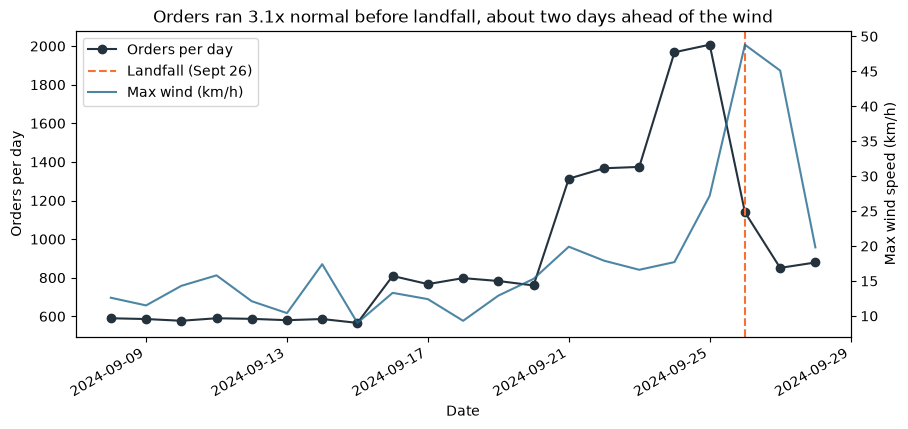

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(merged['date'], merged['orders'], marker='o', color='#24323E', label='Orders per day')
ax.axvline(LANDFALL, color='#F67132', linestyle='--', label='Landfall (Sept 26)')
ax.set_xlabel('Date')
ax.set_ylabel('Orders per day')

ax2 = ax.twinx()
ax2.plot(merged['date'], merged['windspeed_10m_max'], color='#21688D', alpha=0.8, label='Max wind (km/h)')
ax2.set_ylabel('Max wind speed (km/h)')

ax.set_title(f'Orders ran {multiple:.1f}x normal before landfall, about two days ahead of the wind')
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left')
fig.autofmt_xdate()
plt.show()

---

## Before you leave

Nothing to turn in from this notebook. Make sure these are true:

- Your charter is committed to the repo and submitted in Canvas
- Everyone on the team has cloned the repo (with the new data files) and can push to it
- You have a meeting time outside class, and a notebook owner for this week
- `daily_weather` and the merge check are saved in your repo (scratch is fine), ready to run on your real sales data once your cleaning is done

Friday's Midterm Checkpoint (Lab 09) asks for the eight things listed at the kickoff. Recipe 1 is item 4, and Recipe 5 is a start on item 5.